In [1]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

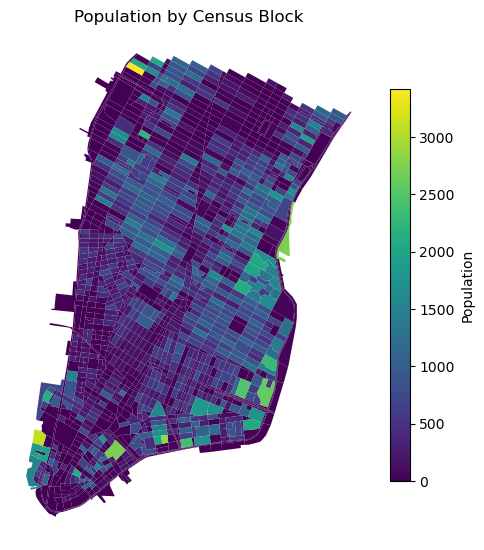

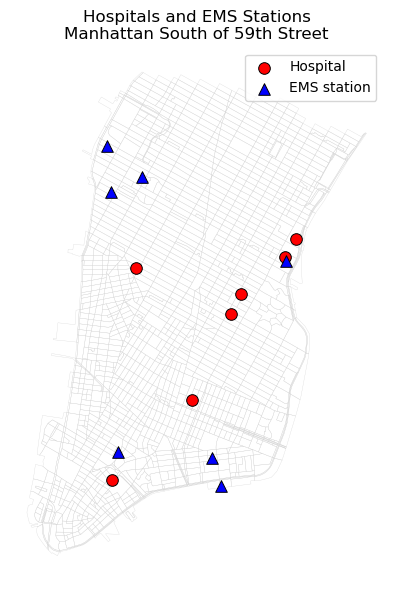

In [2]:
# ---------------------------------------------------------------------
# Load the GeoPackage outputs
# ---------------------------------------------------------------------

population = gpd.read_file("manhattan-data/manhattan_population_blocks.gpkg")
facilities = gpd.read_file("manhattan-data/manhattan_hospitals_ems.gpkg")


# ---------------------------------------------------------------------
# Population map
# ---------------------------------------------------------------------

fig, ax = plt.subplots(figsize=(5, 6))

population.plot(
    ax=ax,
    column="POP20",
    cmap="viridis",
    linewidth=0,
    legend=True,
    legend_kwds={
        "label": "Population",
        "shrink": 0.7,
    },
)

ax.set_title("Population by Census Block")
ax.set_axis_off()

plt.tight_layout()
plt.show()


# ---------------------------------------------------------------------
# Hospitals and EMS stations
# ---------------------------------------------------------------------

fig, ax = plt.subplots(figsize=(5, 6))

# Plot a light population/block geography as the background
population.plot(
    ax=ax,
    facecolor="none",
    edgecolor="lightgray",
    linewidth=0.2,
)

# Separate the two facility types
hospitals = facilities[
    facilities["asset_type"].str.lower() == "hospital"
]

ems = facilities[
    facilities["asset_type"].str.lower() == "ems station"
]

# Plot hospitals
hospitals.plot(
    ax=ax,
    marker="o",
    markersize=70,
    color="red",
    edgecolor="black",
    linewidth=0.7,
    label="Hospital",
)

# Plot EMS stations
ems.plot(
    ax=ax,
    marker="^",
    markersize=70,
    color="blue",
    edgecolor="black",
    linewidth=0.7,
    label="EMS station",
)

ax.set_title("Hospitals and EMS Stations\nManhattan South of 59th Street")
ax.legend()
ax.set_axis_off()

plt.tight_layout()
plt.show()



In [3]:
from datetime import timedelta

import numpy as np
import geopandas as gpd
import pandas as pd


def generate_day_of_incidents(
    population_gdf,
    date,
    rate_per_1000_per_day=5.0, # rate per 1000 residents per day
    population_column="POP20",
    random_seed=None,
):
    """
    Generate a synthetic day of incidents.

    Incident counts are Poisson-distributed and proportional to
    Census-block population.

    Each incident is assigned the representative point of its
    corresponding Census block.

    Returns
    -------
    GeoDataFrame
        Columns include:
            incident_id
            date
            timestamp
            block_index
            population
            expected_incidents
            latitude
            longitude
            geometry
    """

    rng = np.random.default_rng(random_seed)

    blocks = population_gdf.copy()

    blocks = blocks[
        blocks[population_column].notna()
        & (blocks[population_column] > 0)
        & blocks.geometry.notna()
    ].copy()

    # Expected incidents per block
    blocks["expected_incidents"] = (
        blocks[population_column]
        * rate_per_1000_per_day
        / 1000.0
    )

    # Poisson draw for the number of incidents in each block
    blocks["n_incidents"] = rng.poisson(
        blocks["expected_incidents"].to_numpy()
    )

    # Representative point for every block
    blocks["representative_point"] = (
        blocks.geometry.representative_point()
    )

    # Coordinates should be longitude/latitude
    blocks_wgs84 = blocks.to_crs("EPSG:4326")

    incident_records = []

    incident_id = 0
    start = pd.Timestamp(date).normalize()

    for block_index, block in blocks_wgs84.iterrows():

        n = int(block["n_incidents"])

        if n == 0:
            continue

        point = block["representative_point"]

        latitude = point.y
        longitude = point.x

        for _ in range(n):

            # Random occurrence time during the day
            seconds_since_midnight = rng.uniform(
                0,
                24 * 60 * 60,
            )

            timestamp = (
                start
                + pd.to_timedelta(
                    seconds_since_midnight,
                    unit="s",
                )
            )

            incident_records.append(
                {
                    "incident_id": incident_id,
                    "date": start.date(),
                    "timestamp": timestamp,
                    "block_index": block_index,
                    "population": block[population_column],
                    "expected_incidents": block["expected_incidents"],
                    "latitude": latitude,
                    "longitude": longitude,
                    "geometry": point,
                }
            )

            incident_id += 1

    incidents = gpd.GeoDataFrame(
        incident_records,
        geometry="geometry",
        crs="EPSG:4326",
    )

    # Chronological order
    incidents = (
        incidents
        .sort_values("timestamp")
        .reset_index(drop=True)
    )

    return incidents

In [4]:
incidents = generate_day_of_incidents(
    population,
    date="2026-09-23",
    rate_per_1000_per_day=0.1,
    random_seed=42,
)
print(len(incidents))
incidents.head()

56


,incident_id,date,timestamp,block_index,population,expected_incidents,latitude,longitude,geometry
0,14,2026-09-23,2026-09-23 00:34:31.038717615,604,720,0.0720,211829.581642,989182.832766,POINT (989182.83277 211829.58164)
1,40,2026-09-23,2026-09-23 00:51:41.663751036,1296,215,0.0215,203835.493836,984247.604410,POINT (984247.60441 203835.49384)
2,22,2026-09-23,2026-09-23 00:57:44.208853008,794,171,0.0171,205985.249871,983127.835753,POINT (983127.83575 205985.24987)
3,44,2026-09-23,2026-09-23 00:58:10.493371963,1356,648,0.0648,203320.379062,987329.353391,POINT (987329.35339 203320.37906)
4,48,2026-09-23,2026-09-23 01:04:57.914029282,1486,805,0.0805,215981.975759,985312.204825,POINT (985312.20483 215981.97576)


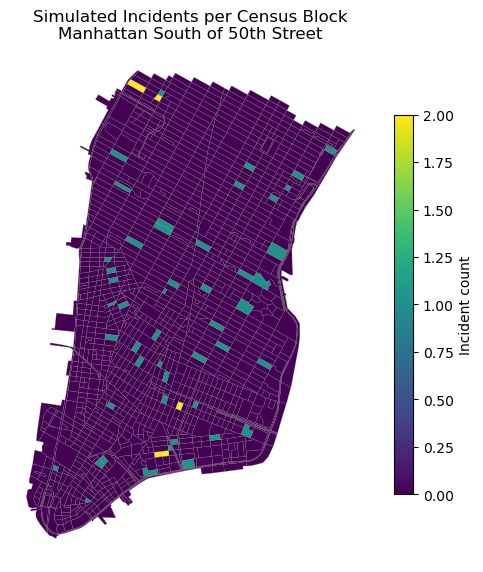

In [5]:
# Count incidents in each Census block
counts = (
    incidents
    .groupby("block_index")
    .size()
    .rename("incident_count")
)


# Join counts back to Census blocks
population["incident_count"] = (
    population.index.to_series()
    .map(counts)
    .fillna(0)
    .astype(int)
)


# Plot
fig, ax = plt.subplots(figsize=(5, 6))

population.plot(
    ax=ax,
    column="incident_count",
    cmap="viridis",
    linewidth=0.15,
    edgecolor="gray",
    legend=True,
    legend_kwds={
        "label": "Incident count",
        "shrink": 0.7,
    },
)

ax.set_title(
    "Simulated Incidents per Census Block\n"
    "Manhattan South of 50th Street"
)

ax.set_axis_off()

plt.tight_layout()
plt.show()